# 05 — Reinforcement learning: decision policy + RLCD fine-tune

**Part A** — the contextual-bandit decision policy (REINFORCE over the SVM
AI-probability + stylometric context): chooses `auto-human` / `review` /
`auto-AI` per document. Evaluated from its saved checkpoint with the selective
classification view (coverage, selective error, expected net cost) and the PAN
abstention metrics (c@1, F0.5u) against grid-tuned fixed thresholds.

**Part B** — the deployed TextCNN fine-tuned with RLCD, evaluated from its
saved checkpoint against its supervised base.

No retraining anywhere: both checkpoints are loaded from `models/`.

In [1]:
import joblib
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from scipy import special

from aitextd import loaders, metrics, paths, plots, registry, splits
from aitextd.training import encode_tokens, predict_probs

SEED = 42
RUN_TRAINING = False  # True: rerun the complete training procedures below

torch.manual_seed(SEED)
torch.set_num_threads(8)

/home/ehsan/Mount/AITextDetection/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# Context = SVM AI-probability + the style features, standardized on the v1
# training rows. The held-out rows are v1 rows, so they index straight into it.
X = joblib.load(paths.TFIDF_X_JOBLIB)
y_all = pd.read_csv(paths.PROCESSED_CSV, usecols=["aiGenerated"])["aiGenerated"].to_numpy()
indices = joblib.load(paths.DATA_DIR / "split_indices.joblib")
train_idx, test_idx = indices["train_idx"], indices["test_idx"]

vectorizer = joblib.load(paths.TFIDF_VECTORIZER_JOBLIB)
tfidf_dim = len(vectorizer.get_feature_names_out())
svm = joblib.load(paths.model_path("svModel.joblib"))
p_svm = special.expit(svm.decision_function(X[:, :tfidf_dim]))
style = np.asarray(X[:, tfidf_dim:].todense())
C = np.column_stack([p_svm, style]).astype(np.float32)

MU, SD = C[train_idx].mean(axis=0), C[train_idx].std(axis=0) + 1e-8
CZ = (C - MU) / SD

heldout = splits.deployed_heldout_frame()
tokenized = splits.v1_tokens()
held_rows = heldout["v1_row"].to_numpy()
heldout_tokens = [tokenized[row] for row in held_rows]
y_held = heldout["label_binary"].to_numpy()
print(f"context matrix {CZ.shape} (p_svm + {CZ.shape[1] - 1} style features) | held-out rows {len(held_rows)}")

/home/ehsan/Mount/AITextDetection/.venv/lib/python3.12/site-packages/sklearn/base.py:525: InconsistentVersionWarning: Trying to unpickle estimator TfidfTransformer from version 1.6.1 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/home/ehsan/Mount/AITextDetection/.venv/lib/python3.12/site-packages/sklearn/base.py:525: InconsistentVersionWarning: Trying to unpickle estimator TfidfVectorizer from version 1.6.1 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


context matrix (21092, 11) (p_svm + 10 style features) | held-out rows 4056


## Part A — contextual bandit (auto-human / review / auto-AI)

In [3]:
REWARD_AUTO_CORRECT, REWARD_AUTO_WRONG, REWARD_REVIEW = 1.0, -3.0, -0.1
COST_FP, COST_FN, COST_REVIEW = 3.0, 1.0, 0.1  # operational costs: false accusations dominate


def reward_of(action, label):
    return np.where(
        action == 1, REWARD_REVIEW, np.where(action == label, REWARD_AUTO_CORRECT, REWARD_AUTO_WRONG)
    )


def policy_report(action, label):
    """Selective-classification + PAN abstention view of one 3-way policy."""
    auto = action != 1
    fp_auto = int(((action == 2) & (label == 0)).sum())
    fn_auto = int(((action == 0) & (label == 1)).sum())
    return {
        "coverage": round(float(auto.mean()), 4),
        "auto_accuracy": round(float((action[auto] == label[auto]).mean()), 4) if auto.any() else None,
        "auto_fpr": round(fp_auto / max(int((label == 0).sum()), 1), 4),
        "auto_fnr": round(fn_auto / max(int((label == 1).sum()), 1), 4),
        "utility_mean": round(float(reward_of(action, label).mean()), 4),
        "expected_cost": round(
            float((COST_FP * fp_auto + COST_FN * fn_auto + COST_REVIEW * int((action == 1).sum())) / len(label)), 4
        ),
        "c_at_1": round(metrics.c_at_1(label, (action == 2).astype(int), action == 1), 4),
        "f0_5u": metrics.f0_5u(label, (action == 2).astype(int), action == 1),
    }

In [4]:
# Grid-tuned fixed thresholds on the v1 training rows (the honest baseline)
best = None
for lo in np.arange(0.05, 0.95, 0.05):
    for hi in np.arange(lo + 0.05, 1.0, 0.05):
        action = np.where(C[train_idx, 0] >= hi, 2, np.where(C[train_idx, 0] >= lo, 1, 0))
        utility = reward_of(action, y_all[train_idx]).mean()
        if best is None or utility > best[0]:
            best = (utility, lo, hi)
_, LO_STAR, HI_STAR = best
print(f"fixed thresholds tuned on train: review >= {LO_STAR:.2f}, auto-AI >= {HI_STAR:.2f}")


def fixed_policy(p):
    return np.where(p >= HI_STAR, 2, np.where(p >= LO_STAR, 1, 0))


POLICY_FILE = paths.model_path("rlPolicyModel.pt")
ckpt = torch.load(POLICY_FILE, map_location="cpu", weights_only=False)
cfg = ckpt["config"]
policy = nn.Sequential(nn.Linear(cfg["n_features"], cfg["hidden"]), nn.ReLU(), nn.Linear(cfg["hidden"], 3))
policy.load_state_dict(ckpt["state_dict"])
policy.eval()
print("loaded checkpoint rlPolicyModel.pt")

fixed thresholds tuned on train: review >= 0.35, auto-AI >= 0.95
loaded checkpoint rlPolicyModel.pt


## REINFORCE training procedure (complete, flag-guarded)

The **complete** procedure that produced `rlPolicyModel.pt`: the policy network
over the standardized context matrix, REINFORCE with sampled actions and a
moving reward baseline, trained on the **full** v1 training rows for 5 epochs,
then saved with its config (feature standardization, reward scale, tuned fixed
thresholds) in the format the serving loader rebuilds.

**Not executed here** (`RUN_TRAINING = False`); the evaluation cells below run
unchanged either way.

In [ ]:
if RUN_TRAINING:
    EPOCHS, BATCH, LR, HIDDEN = 5, 256, 1e-3, 64

    policy = nn.Sequential(nn.Linear(CZ.shape[1], HIDDEN), nn.ReLU(), nn.Linear(HIDDEN, 3))
    optimizer = torch.optim.Adam(policy.parameters(), lr=LR)
    Ct = torch.tensor(CZ[train_idx], dtype=torch.float32)
    yt = torch.tensor(y_all[train_idx], dtype=torch.long)
    baseline = 0.0
    for epoch in range(1, EPOCHS + 1):
        perm = torch.randperm(len(Ct))
        total = 0.0
        for start in range(0, len(perm), BATCH):
            idx = perm[start : start + BATCH]
            logits = policy(Ct[idx])
            action = torch.multinomial(torch.softmax(logits, -1), 1).squeeze(-1)
            r = torch.tensor(
                [REWARD_REVIEW if a == 1 else (REWARD_AUTO_CORRECT if a == lb else REWARD_AUTO_WRONG)
                 for a, lb in zip(action.tolist(), yt[idx].tolist())],
                dtype=torch.float32,
            )
            advantage = r - baseline
            baseline = 0.95 * baseline + 0.05 * r.mean().item()
            logp = torch.log_softmax(logits, -1)[torch.arange(len(idx)), action]
            loss = -(advantage * logp).mean()
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            total += float(loss) * len(idx)
        print(f"epoch {epoch}/{EPOCHS} loss={total / len(perm):.4f} baseline={baseline:.3f}")

    torch.save({
        "state_dict": policy.state_dict(),
        "config": {
            "n_features": int(CZ.shape[1]), "hidden": HIDDEN,
            "actions": ["auto_human", "review", "auto_ai"],
            "reward": {"auto_correct": REWARD_AUTO_CORRECT, "auto_wrong": REWARD_AUTO_WRONG, "review": REWARD_REVIEW},
            "feature_mean": MU.tolist(), "feature_std": SD.tolist(),
            "context": ["p_svm"] + [f"style_{i}" for i in range(CZ.shape[1] - 1)],
            "fixed_thresholds": {"review": float(LO_STAR), "auto_ai": float(HI_STAR)},
        },
    }, paths.model_path("rlPolicyModel.pt"))
    print("saved rlPolicyModel.pt — the evaluation below scores the fresh policy")
else:
    print("RUN_TRAINING=False — the deployed rlPolicyModel.pt is used below")

In [5]:
with torch.no_grad():
    action_probs = torch.softmax(policy(torch.tensor(CZ[held_rows], dtype=torch.float32)), dim=-1).numpy()

bandit_results = {
    "reinforce_policy": policy_report(action_probs.argmax(axis=1), y_held),
    "fixed_thresholds": policy_report(fixed_policy(C[held_rows, 0]), y_held),
    "always_review": policy_report(np.ones(len(held_rows), dtype=int), y_held),
    "no_review_argmax": policy_report((C[held_rows, 0] >= 0.5).astype(int) * 2, y_held),
}
pd.DataFrame(bandit_results).T

,coverage,auto_accuracy,auto_fpr,auto_fnr,utility_mean,expected_cost,c_at_1,f0_5u
reinforce_policy,0.4714,0.9927,0.0000,0.0066,0.4047,0.0563,0.9927,0.0000
fixed_thresholds,0.4569,0.9995,0.0000,0.0005,0.4016,0.0546,0.9995,0.0000
always_review,0.0000,NaN,0.0000,0.0000,-0.1000,0.1000,0.0000,0.0000
no_review_argmax,1.0000,0.4795,0.0021,0.0038,-1.0819,0.0049,0.9970,0.9977


<Axes: title={'left': 'Decision policies — mean utility on the held-out set'}, xlabel='mean utility'>

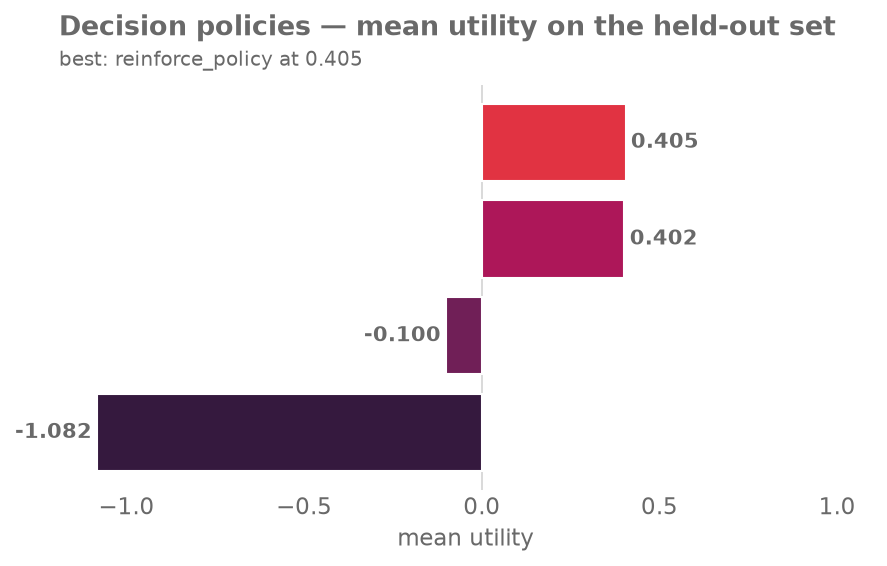

In [6]:
plots.bar_series(
    pd.Series({k: v["utility_mean"] for k, v in bandit_results.items()}),
    "Decision policies — mean utility on the held-out set",
    "mean utility",
)

AURC (0.5-1.0 coverage): 0.1756


<Axes: title={'left': 'REINFORCE policy — risk-coverage on the held-out set'}, xlabel='coverage (share of documents auto-decided)', ylabel='selective error'>

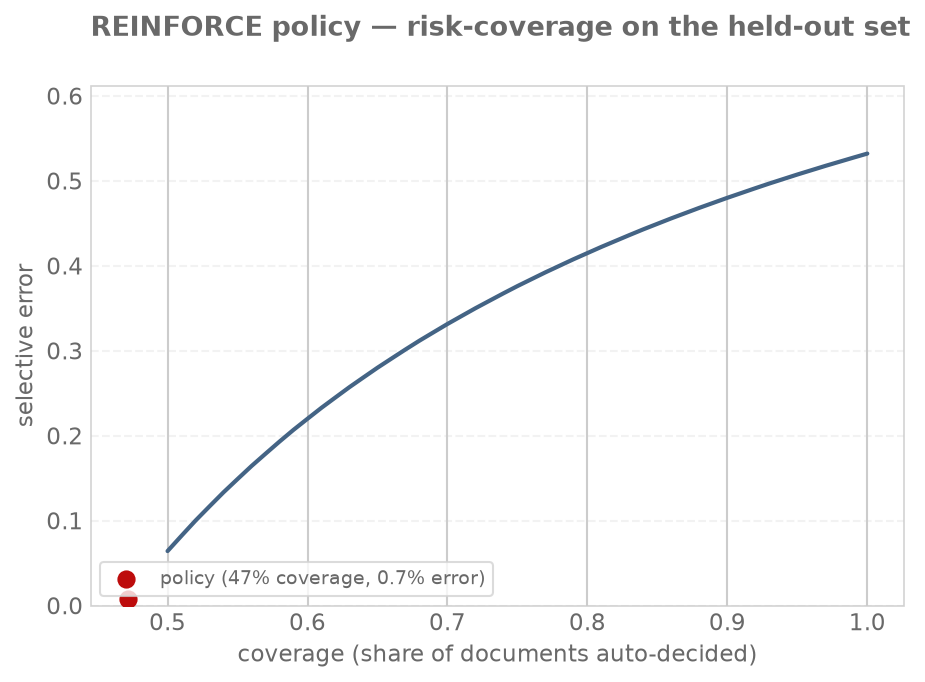

In [7]:
# Risk-coverage: selective error among auto-decided documents as the
# accepted share grows, ranked by the confidence of the chosen AUTO action
# (review rows rank last).
chosen = action_probs.argmax(axis=1)
auto_conf = np.where(chosen == 1, -1.0, action_probs.max(axis=1))
correct_auto = (chosen != 1) & ((chosen == 2) == (y_held == 1))
order = np.argsort(-auto_conf)
coverages = np.linspace(0.5, 1.0, 51)
risks = [1.0 - correct_auto[order[: int(c * len(order))]].mean() for c in coverages]
aurc = float(np.trapezoid(risks, coverages))
print(f"AURC (0.5-1.0 coverage): {aurc:.4f}")
plots.risk_coverage(
    coverages, risks,
    operating_point=(bandit_results["reinforce_policy"]["coverage"],
                     1 - bandit_results["reinforce_policy"]["auto_accuracy"]),
    title="REINFORCE policy — risk-coverage on the held-out set",
)

## Part B — RLCD fine-tune vs supervised TextCNN

### RLCD fine-tune procedure (complete, flag-guarded)

The **complete** RLCD loop that produced `textcnnRlcdModel.pt`: soft targets
distilled from the supervised TextCNN (0.8 ground-truth / 0.2 teacher), noisy
logit candidates scored by spherical + ranked-probability rewards, a REINFORCE
term plus a soft cross-entropy anchor. **Not executed here**
(`RUN_TRAINING = False`).

In [ ]:
if RUN_TRAINING:
    import torch.nn.functional as F
    from sklearn.model_selection import train_test_split

    from aitextd.architectures import TextCNNClassifier

    RLCD_EPOCHS, RLCD_SUBSAMPLE, RLCD_BATCH, RLCD_LR = 2, 6000, 64, 5e-5
    NOISE_SIGMA, K_NOISE, W_SPH, W_RPS = (0.4, 0.1), 4, 0.75, 1.0
    LABEL_WEIGHT, TEACHER_WEIGHT, TARGET_CLIP = 0.8, 0.2, (0.02, 0.98)

    sup_ckpt = torch.load(paths.model_path("textcnnModel.pt"), map_location="cpu", weights_only=False)
    vocab, sup_config = sup_ckpt["vocab"], sup_ckpt["config"]

    def make_textcnn():
        return TextCNNClassifier(
            len(vocab), sup_config["embed_dim"], sup_config["n_filters"],
            tuple(sup_config["kernel_sizes"]), pad_idx=sup_config["pad_idx"],
            dropout=sup_config.get("dropout", 0.3),
        )

    teacher = make_textcnn()
    teacher.load_state_dict(sup_ckpt["state_dict"])
    teacher.eval()

    rlcd_model = make_textcnn()
    rlcd_model.load_state_dict(sup_ckpt["state_dict"])  # start from the supervised weights

    train_sub = np.asarray(train_test_split(
        train_idx, train_size=RLCD_SUBSAMPLE, random_state=SEED, stratify=y_all[train_idx]
    )[0])
    X_train_seq = encode_tokens([tokenized[i] for i in train_sub], vocab, sup_config["max_len"])

    # soft targets: 0.8 ground truth + 0.2 teacher probability, clipped for stability
    t_ai = np.clip(
        LABEL_WEIGHT * y_all[train_sub] + TEACHER_WEIGHT * predict_probs(teacher, X_train_seq),
        *TARGET_CLIP,
    )
    targets = torch.tensor(np.stack([1.0 - t_ai, t_ai], axis=1), dtype=torch.float32)

    optimizer = torch.optim.AdamW(rlcd_model.parameters(), lr=RLCD_LR)
    for epoch in range(RLCD_EPOCHS):
        sigma = NOISE_SIGMA[0] + (NOISE_SIGMA[1] - NOISE_SIGMA[0]) * epoch / max(1, RLCD_EPOCHS - 1)
        rlcd_model.train()
        order = np.random.default_rng(SEED + epoch).permutation(len(train_sub))
        total = 0.0
        for start in range(0, len(order), RLCD_BATCH):
            idx = order[start : start + RLCD_BATCH]
            xb, tb = X_train_seq[idx], targets[idx]
            logits = rlcd_model(xb)
            clean2 = torch.stack([-logits, logits], dim=-1)
            eps = torch.randn((K_NOISE, *clean2.shape)) * sigma
            noisy = clean2.detach().unsqueeze(0) + eps
            probs = torch.softmax(noisy, dim=-1)
            sph = (probs * tb.unsqueeze(0)).sum(-1) / probs.pow(2).sum(-1).sqrt()
            rps = -0.5 * ((torch.cumsum(probs, -1) - torch.cumsum(tb, -1).unsqueeze(0)) ** 2).sum(-1)
            reward = W_SPH * sph + W_RPS * rps
            advantage = (reward - reward.mean(0, keepdim=True)) / (reward.std() + 1e-6)
            logp = -(((noisy - clean2.unsqueeze(0)) ** 2).sum(-1)) / (2 * sigma**2)
            loss = -(advantage * logp).mean() + F.binary_cross_entropy_with_logits(logits, tb[:, 1])
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            total += float(loss) * len(idx)
        print(f"epoch {epoch + 1}/{RLCD_EPOCHS} loss={total / len(order):.4f} sigma={sigma:.2f}")

    torch.save(
        {"state_dict": rlcd_model.state_dict(), "vocab": vocab, "config": sup_config},
        paths.model_path("textcnnRlcdModel.pt"),
    )
    print("saved textcnnRlcdModel.pt — the evaluation below scores the fresh fine-tune")
else:
    print("RUN_TRAINING=False — the deployed textcnnRlcdModel.pt is used below")

In [5]:
supervised = loaders.load_textcnn_model({"filename": "textcnnModel.pt"})
rlcd = loaders.load_textcnn_model({"filename": "textcnnRlcdModel.pt"})

X_seq = encode_tokens(heldout_tokens, supervised["vocab"], supervised["config"]["max_len"])
rlcd_reports, rlcd_probs = {}, {}
for mid, bundle in (("textcnn_supervised", supervised), ("textcnn_rlcd", rlcd)):
    probs = predict_probs(bundle["model"], X_seq)
    rlcd_probs[mid] = probs
    rlcd_reports[mid] = metrics.evaluation_report(y_held, probs)
print("evaluated: textcnn_supervised, textcnn_rlcd")

evaluated: textcnn_supervised, textcnn_rlcd


In [6]:
metrics.evaluation_table(rlcd_reports, metrics.RANKING_COLUMNS)

,roc_auc,pr_auc,pauc_5,tpr_at_fpr_1,tpr_at_fpr_5,fpr_at_tpr_90
model,,,,,,
textcnn_supervised,0.9994,0.9995,0.9937,0.9934,0.9981,0.0005
textcnn_rlcd,0.9994,0.9995,0.9937,0.9934,0.9981,0.0005


In [10]:
metrics.evaluation_table(rlcd_reports, metrics.THRESHOLD_COLUMNS)

,accuracy,balanced_accuracy,macro_f1,mcc,kappa,precision,recall,f1,fpr
model,,,,,,,,,
textcnn_supervised,0.9916,0.9916,0.9916,0.9832,0.9832,0.9910,0.9929,0.9919,0.0097
textcnn_rlcd,0.9911,0.9911,0.9911,0.9822,0.9822,0.9919,0.9910,0.9915,0.0087


<Axes: title={'left': 'TextCNN: supervised vs RLCD fine-tune'}>

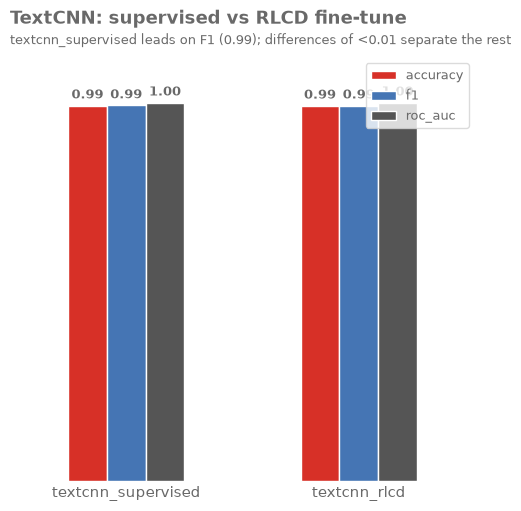

In [11]:
plots.metric_bars(rlcd_reports, "TextCNN: supervised vs RLCD fine-tune")

<Axes: title={'left': 'TextCNN: supervised vs RLCD — ROC, low-FPR region'}, xlabel='False Positive Rate (log scale)', ylabel='True Positive Rate'>

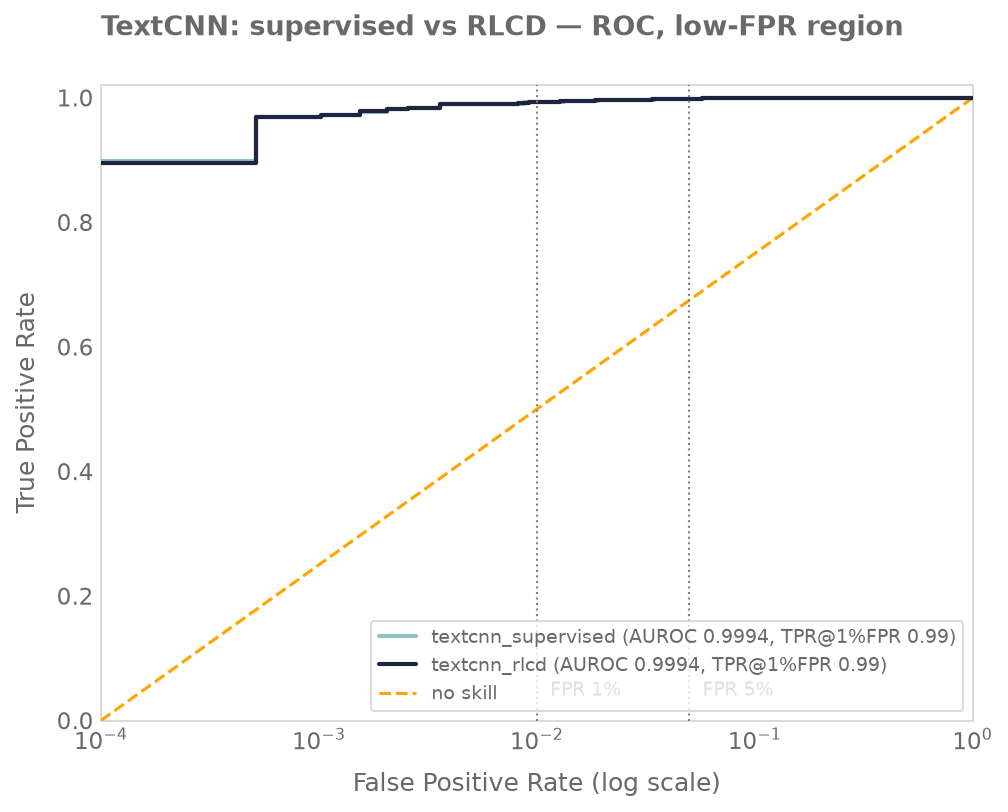

In [12]:
plots.roc_curves_log(y_held, rlcd_probs, "TextCNN: supervised vs RLCD — ROC, low-FPR region")

In [13]:
from aitextd import predictors
from aitextd.text import preprocess_persian_text

sample = "هوش مصنوعی یکی از مهم‌ترین فناوری‌های قرن بیست‌ویکم است و تأثیر عمیقی بر اقتصاد گذاشته است."
cleaned = preprocess_persian_text(sample)
print("serving-path prediction (RLCD checkpoint):",
      round(predictors.PREDICTORS["pytorch-textcnn"](rlcd, sample, cleaned, {}), 4))

serving-path prediction (RLCD checkpoint): 1.0


## Summary

- `bandit_results` — the REINFORCE policy vs grid-tuned fixed thresholds vs
  two baselines, with coverage / selective error / expected cost / c@1 / F0.5u.
- Risk-coverage curve + AURC quantifies how cleanly the policy defers the
  ambiguous cases (E-AURC needs an oracle ranking and is not computed here).
- RLCD lands at parity with its supervised base — an ensemble-optional
  variant, kept out of the vote by `ensembleWeight: 0` in models.json.